# Compare TRICK & TREAT

In [8]:
# Import useful packages
import matplotlib.pyplot as plt
import numpy as np
from paarti.utils import maos_utils
from paarti import psfs, psf_plots
from pathlib import Path
from astropy import units as u

# Import maos scripts to read .bin files
import sys
sys.path.append('/u/nstieg/code/latest_maos/maos/')
from scripts import readbin


%matplotlib inline

# Set up parameters
seed = 1 # We ran every sim at a seed of 1

In [9]:
def get_sorted_values(base_output_directory, run_num=4, seed=1):
    all_dirs = base_output_directory.glob("A_comparison_tt_mag_*")

    run_files = []

    if run_num is not None:
        for d in all_dirs:
            if d.is_dir() and f"_run{run_num}" in d.name:
                run_files.append(d)
    else:
        # Match only A_comparison_tt_mag_{mag}/ and not _run#
        for d in all_dirs:
            if d.is_dir() and "_run" not in d.name:
                run_files.append(d)

    print(f"Found {len(run_files)} run files for run_num={run_num}")

    # if run_num is not None:
    #     run_files = [run_file for run_file in base_output_directory.glob(f"A_comparison_tt_mag_*_run{run_num}*")]
    # else:
    #     run_files = [run_file for run_file in base_output_directory.glob(f"A_comparison_tt_mag_*")]
    ngs_mags = []
    j_band_strehl = []
    h_band_strehl = []
    k_band_strehl = []
    j_band_fwhm_e = []
    k_band_fwhm_e = []
    h_band_fwhm_e = []
    median_total_ol_error = []
    median_total_error = []
    median_tt_error = []
    median_ho_error = []
    median_lgs_error = []
    median_ngs_tt_error = []
    median_ngs_total_error = []

    for run_file in run_files:
        directory = str(run_file)
        if directory[-1] != "/":
            directory += "/"

        # Get values
        # try:
        # get ngs_magnitude from directory name A_comparison_tt_mag_{ngs_magnitude}
        is_trick_string = "TRICK" in run_file.parent.parent.name # These are formatted A_comparison_tt_mag_{mag}_run{#}/
        is_treat_string = "TREAT" in run_file.parent.parent.name # These are formatted A_comparison_tt_mag_{mag}_run{#}_{freq}Hz
        is_basic_run = len(run_file.name.split("_")) == 5 # These are ones that are formatted A_comparison_tt_mag_{mag}/

        print("Processing directory: ", directory)
        to_print_str = ""
        if is_trick_string:
            to_print_str += "TRICK "
        if is_treat_string:
            to_print_str += "TREAT "
        if is_basic_run:
            to_print_str += "BASIC_RUN "
        else:
            to_print_str += "LATER RUN "
        print(to_print_str)

        if is_treat_string:
            ngs_mag_str = str(run_file).split("A_comparison_tt_mag_")[-1].split("_")[0]
        elif is_trick_string and not is_basic_run:
            ngs_mag_str = str(run_file).split("A_comparison_tt_mag_")[-1].split("_")[0]
        elif is_trick_string and is_basic_run:
            ngs_mag_str = directory.split("A_comparison_tt_mag_")[-1][:-1] # Remove trailing slash
        ngs_mag = float(ngs_mag_str)
        print("Found NGS magnitude: ", ngs_mag)
        ngs_mags.append(ngs_mag)

        # Read in values from directory
        mets = maos_utils.get_psf_metrics_over_field(directory, seed=seed)
        x, y, w, strehl, fwhm_g, fwhm_e, r_ee50, r_ee80 = mets
        strehl = strehl[0]
        fwhm_e = fwhm_e[0]
        assert(len(strehl) == 5), "Strehls not of length 5, something is wrong"
        j_band_strehl.append(strehl[-3])
        h_band_strehl.append(strehl[-2])
        k_band_strehl.append(strehl[-1])
        j_band_fwhm_e.append(fwhm_e[-3])
        h_band_fwhm_e.append(fwhm_e[-2])
        k_band_fwhm_e.append(fwhm_e[-1])

        # Read in closed-loop tip-tilt errors from the .bin file
        p = Path(directory)
        res_bin_file = list(p.glob("*Res_*.bin"))[0]
        res = readbin.readbin(str(res_bin_file))

        # Function to get WFE from stored WFV
        def wfe_from_wfv(wfv):
            return np.sqrt(wfv * u.m * u.m).to(u.nm)

        def get_median_wfe(wfe):
            burn_in_index = 300
            return np.median(wfe[burn_in_index:].to_value(u.nm))

        ## Get errors for all stored residuals
        # Open Loop
        total_ol_errors_nm = wfe_from_wfv(res[0][:, 0]) # Total error in open loop
        this_median_ol_total_error = get_median_wfe(total_ol_errors_nm)
        median_total_ol_error.append(this_median_ol_total_error)

        # Closed Loop
        total_errors_nm = wfe_from_wfv(res[2][:, 0]) # Total error in closed loop
        this_median_total_error = get_median_wfe(total_errors_nm)
        median_total_error.append(this_median_total_error)
        
        tt_errors_nm = wfe_from_wfv(res[2][:, 1]) # Tip Tilt in closed loop
        this_median_tt_error = get_median_wfe(tt_errors_nm)
        median_tt_error.append(this_median_tt_error)

        ho_errors_nm = wfe_from_wfv(res[2][:, 2]) # High order error in closed loop
        this_median_ho_error = get_median_wfe(ho_errors_nm)
        median_ho_error.append(this_median_ho_error)

        # Split tomography closed loop
        lgs_errors_nm = wfe_from_wfv(res[3][:, 0]) # LGS error in closed loop
        this_median_lgs_error = get_median_wfe(lgs_errors_nm)
        median_lgs_error.append(this_median_lgs_error)

        ngs_tt_errors_nm = wfe_from_wfv(res[3][:, 1]) # NGS tip-tilt error in closed loop
        this_median_ngs_tt_error = get_median_wfe(ngs_tt_errors_nm)
        median_ngs_tt_error.append(this_median_ngs_tt_error)

        ngs_total_errors_nm = wfe_from_wfv(res[3][:, 2]) # NGS total error in closed loop
        this_median_ngs_total_error = get_median_wfe(ngs_total_errors_nm)
        median_ngs_total_error.append(this_median_ngs_total_error)

            
        # except Exception as e:
        #     print(f"Error processing directory {directory}: {e}")

    # Sort values by ngs_mags
    sorted_pairs = sorted(zip(ngs_mags,
                              j_band_strehl, h_band_strehl, k_band_strehl,
                              j_band_fwhm_e, h_band_fwhm_e, k_band_fwhm_e,
                              median_total_ol_error,
                              median_total_error, median_tt_error, median_ho_error,
                              median_lgs_error, median_ngs_tt_error, median_ngs_total_error))
    sorted_ngs_mags, \
    sorted_j_band_strehl, sorted_h_band_strehl, sorted_k_band_strehl, \
    sorted_j_band_fwhm_e, sorted_h_band_fwhm_e, sorted_k_band_fwhm_e, \
    sorted_median_total_ol_error, \
    sorted_median_total_error, sorted_median_tt_error, sorted_median_ho_error, \
    sorted_median_lgs_error, sorted_median_ngs_tt_error, sorted_median_ngs_total_error = zip(*sorted_pairs)
    sorted_errors = {
        "median_total_ol_error": sorted_median_total_ol_error,
        "median_total_error": sorted_median_total_error,
        "median_tt_error": sorted_median_tt_error,
        "median_ho_error": sorted_median_ho_error,
        "median_lgs_error": sorted_median_lgs_error,
        "median_ngs_tt_error": sorted_median_ngs_tt_error,
        "median_ngs_total_error": sorted_median_ngs_total_error
    }
    return sorted_ngs_mags, sorted_j_band_strehl, sorted_h_band_strehl, sorted_k_band_strehl, sorted_j_band_fwhm_e, sorted_h_band_fwhm_e, sorted_k_band_fwhm_e, sorted_errors
        

## TREAT

In [10]:
treat_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/')
result = get_sorted_values(treat_output_directory, seed=seed, run_num=None)
sorted_treat_ngs_mags, sorted_treat_j_band_strehl, sorted_treat_h_band_strehl, sorted_treat_k_band_strehl, sorted_treat_j_band_fwhm_e, sorted_treat_h_band_fwhm_e, sorted_treat_k_band_fwhm_e, sorted_treat_errors = result
sorted_treat_median_tt_error = sorted_treat_errors["median_tt_error"]

Found 21 run files for run_num=None
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_11.0/
TREAT BASIC_RUN 
Found NGS magnitude:  11.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_11.0/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_16.5/
TREAT BASIC_RUN 
Found NGS magnitude:  16.5
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_16.5/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_10.5/
TREAT BASIC_RUN 
Found NGS magnitude:  10.5
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_10.5/ for simulation results...
xx =  0.0 yy =  0.0
Processing

## TRICK

In [11]:
trick_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/')
result = get_sorted_values(trick_output_directory, seed=seed, run_num=None)
sorted_trick_ngs_mags, sorted_trick_j_band_strehl, sorted_trick_h_band_strehl, sorted_trick_k_band_strehl, sorted_trick_j_band_fwhm_e, sorted_trick_h_band_fwhm_e, sorted_trick_k_band_fwhm_e, sorted_trick_errors = result
sorted_trick_median_tt_error = sorted_trick_errors["median_tt_error"]

Found 21 run files for run_num=None
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_11.0/
TRICK BASIC_RUN 
Found NGS magnitude:  11.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_11.0/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_16.5/
TRICK BASIC_RUN 
Found NGS magnitude:  16.5
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_16.5/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_10.5/
TRICK BASIC_RUN 
Found NGS magnitude:  10.5
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_10.5/ for simulation results...
xx =  0.0 yy =  0.0
Processing

## Plots

In [12]:
# Figure out how big the error bars should be
# For step 1 (old base w/LBWFS as focus), I ran 3 different simulations with 3 different seeds
# We'll call our error bar the standard deviation of those 3 runs which should give an idea of how much
# variability MAOS might give with different RNG
multiple_sim_results = [0.528, 0.533, .551] 
maos_error_bar_size = np.std(multiple_sim_results)
print(f"Error bar (std dev of multiple runs): {maos_error_bar_size}")

Error bar (std dev of multiple runs): 0.009877021593352712


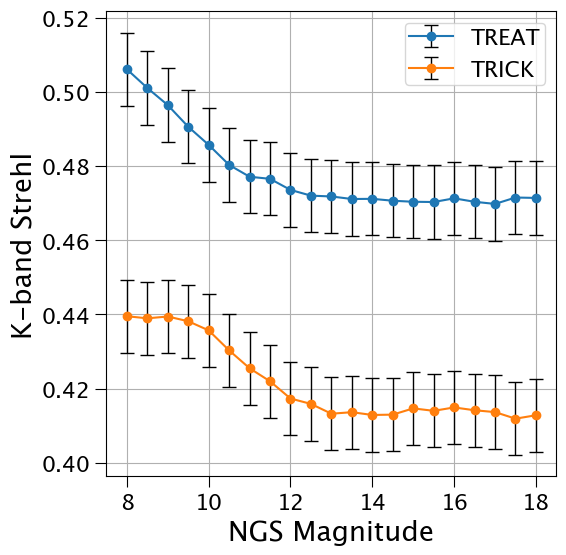

In [13]:
plt.errorbar(sorted_treat_ngs_mags, sorted_treat_k_band_strehl, marker='o', yerr=maos_error_bar_size, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, sorted_trick_k_band_strehl, marker='o', yerr=maos_error_bar_size, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band Strehl')
plt.grid()
plt.legend()
plt.show()

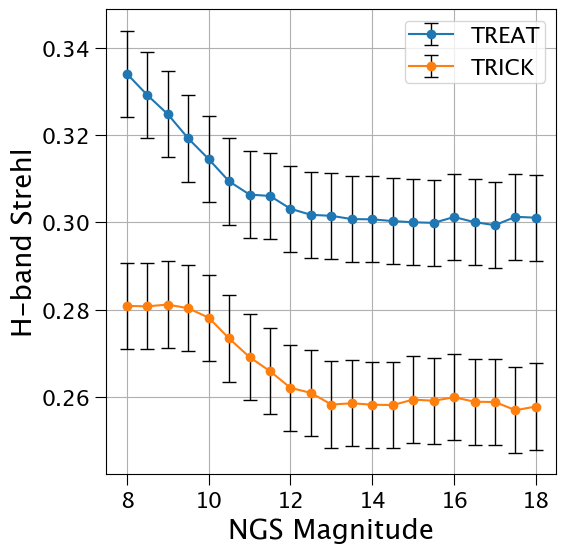

In [14]:
plt.errorbar(sorted_treat_ngs_mags, sorted_treat_h_band_strehl, marker='o', yerr=maos_error_bar_size, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, sorted_trick_h_band_strehl, marker='o', yerr=maos_error_bar_size, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('H-band Strehl')
plt.grid()
plt.legend()
plt.show()

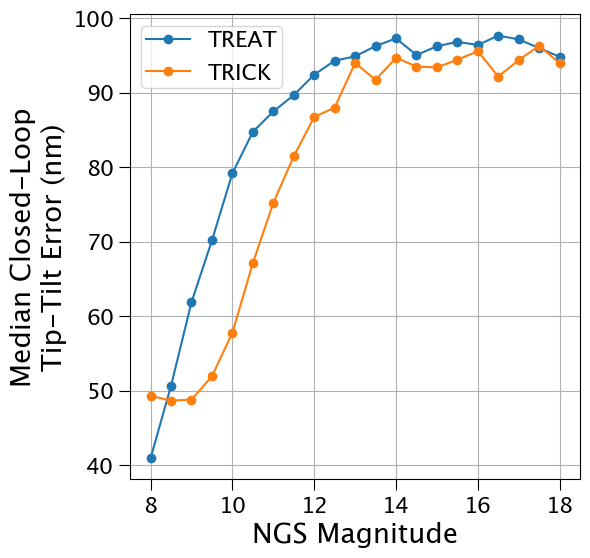

In [15]:
# Look at tip-tilt error as a function of NGS magnitude
plt.plot(sorted_treat_ngs_mags, sorted_treat_median_tt_error, marker='o', label="TREAT")
plt.plot(sorted_trick_ngs_mags, sorted_trick_median_tt_error, marker='o', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed-Loop\nTip-Tilt Error (nm)')
plt.grid()
plt.legend()
plt.show()

## Do the same but for different seeded runs

In [16]:
all_sorted_treat_ngs_mags = []
all_sorted_treat_j_band_strehl = []
all_sorted_treat_h_band_strehl = []
all_sorted_treat_k_band_strehl = []
all_sorted_treat_j_band_fwhm_e = []
all_sorted_treat_h_band_fwhm_e = []
all_sorted_treat_k_band_fwhm_e = []
all_sorted_treat_median_tt_error = []
treat_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/')
num_seeds = 5
for seed in range(1, num_seeds + 1):
    result = get_sorted_values(treat_output_directory, seed=seed)
    sorted_treat_ngs_mags, sorted_treat_j_band_strehl, sorted_treat_h_band_strehl, sorted_treat_k_band_strehl, sorted_treat_j_band_fwhm_e, sorted_treat_h_band_fwhm_e, sorted_treat_k_band_fwhm_e, sorted_treat_errors = result
    sorted_treat_median_tt_error = sorted_treat_errors["median_tt_error"]
    all_sorted_treat_ngs_mags.append(sorted_treat_ngs_mags)
    all_sorted_treat_j_band_strehl.append(sorted_treat_j_band_strehl)
    all_sorted_treat_h_band_strehl.append(sorted_treat_h_band_strehl)
    all_sorted_treat_k_band_strehl.append(sorted_treat_k_band_strehl)
    all_sorted_treat_j_band_fwhm_e.append(sorted_treat_j_band_fwhm_e)
    all_sorted_treat_h_band_fwhm_e.append(sorted_treat_h_band_fwhm_e)
    all_sorted_treat_k_band_fwhm_e.append(sorted_treat_k_band_fwhm_e)
    all_sorted_treat_median_tt_error.append(sorted_treat_median_tt_error)

Found 21 run files for run_num=4
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_17.5_run4_3500Hz/
TREAT LATER RUN 
Found NGS magnitude:  17.5
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_17.5_run4_3500Hz/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_12.0_run4_3500Hz/
TREAT LATER RUN 
Found NGS magnitude:  12.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_12.0_run4_3500Hz/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_9.0_run4_3500Hz/
TREAT LATER RUN 
Found NGS magnitude:  9.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_9.0_run

In [17]:
# Same for TRICK
all_sorted_trick_ngs_mags = []
all_sorted_trick_j_band_strehl = []
all_sorted_trick_h_band_strehl = []
all_sorted_trick_k_band_strehl = []
all_sorted_trick_j_band_fwhm_e = []
all_sorted_trick_h_band_fwhm_e = []
all_sorted_trick_k_band_fwhm_e = []
all_sorted_trick_median_total_ol_error = []
all_sorted_trick_median_total_error = []
all_sorted_trick_median_tt_error = []
all_sorted_trick_median_ho_error = []
all_sorted_trick_median_lgs_error = []
all_sorted_trick_median_ngs_tt_error = []
all_sorted_trick_median_ngs_total_error = []
trick_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/')
num_seeds = 5
for seed in range(1, num_seeds + 1):
    result = get_sorted_values(trick_output_directory, seed=seed)
    sorted_trick_ngs_mags, sorted_trick_j_band_strehl, sorted_trick_h_band_strehl, sorted_trick_k_band_strehl, sorted_trick_j_band_fwhm_e, sorted_trick_h_band_fwhm_e, sorted_trick_k_band_fwhm_e, sorted_trick_errors = result
    sorted_trick_median_total_ol_error = sorted_trick_errors["median_total_ol_error"]
    sorted_trick_median_total_error = sorted_trick_errors["median_total_error"]
    sorted_trick_median_tt_error = sorted_trick_errors["median_tt_error"]
    sorted_trick_median_ho_error = sorted_trick_errors["median_ho_error"]
    sorted_trick_median_lgs_error = sorted_trick_errors["median_lgs_error"]
    sorted_trick_median_ngs_tt_error = sorted_trick_errors["median_ngs_tt_error"]
    sorted_trick_median_ngs_total_error = sorted_trick_errors["median_ngs_total_error"]
    all_sorted_trick_ngs_mags.append(sorted_trick_ngs_mags)
    all_sorted_trick_j_band_strehl.append(sorted_trick_j_band_strehl)
    all_sorted_trick_h_band_strehl.append(sorted_trick_h_band_strehl)
    all_sorted_trick_k_band_strehl.append(sorted_trick_k_band_strehl)
    all_sorted_trick_j_band_fwhm_e.append(sorted_trick_j_band_fwhm_e)
    all_sorted_trick_h_band_fwhm_e.append(sorted_trick_h_band_fwhm_e)
    all_sorted_trick_k_band_fwhm_e.append(sorted_trick_k_band_fwhm_e)
    all_sorted_trick_median_total_ol_error.append(sorted_trick_median_total_ol_error)
    all_sorted_trick_median_total_error.append(sorted_trick_median_total_error)
    all_sorted_trick_median_tt_error.append(sorted_trick_median_tt_error)
    all_sorted_trick_median_ho_error.append(sorted_trick_median_ho_error)
    all_sorted_trick_median_lgs_error.append(sorted_trick_median_lgs_error)
    all_sorted_trick_median_ngs_tt_error.append(sorted_trick_median_ngs_tt_error)
    all_sorted_trick_median_ngs_total_error.append(sorted_trick_median_ngs_total_error)

Found 21 run files for run_num=4
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_16.0_run4/
TRICK LATER RUN 
Found NGS magnitude:  16.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_16.0_run4/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_8.0_run4/
TRICK LATER RUN 
Found NGS magnitude:  8.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_8.0_run4/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_12.5_run4/
TRICK LATER RUN 
Found NGS magnitude:  12.5
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK/outputs/A_comparison_tt_mag_12.5_run4/ for simulation results...
xx =  

In [18]:
# Get the mean & std dev based on the runs at different seeds

## Convert them all to numpy arrays for easier manipulation
# TREAT

# Define a function to regularize the lists. Goes through the results for each of the 5 seeds
# and checks the length of the results. It will either be n or n + 1 depending because not all
# seeds have finished running the latest ngs_mag simulation. Returns an array with a regular 
# rectangular shape by trimming the data from the ngs_mags which haven't run on all seeds yet
def regularize_sim_data_list(list_of_tuples):
    # Get the minimum length of the results across all seeds
    min_length = min(len(tup) for tup in list_of_tuples)
    print(f"Minimum length across seeds: {min_length}")
    
    # Trim each tuple to the minimum length and convert to numpy array
    regularized_arrays = []
    for tup in list_of_tuples:
        trimmed_tup = tup[:min_length]
        regularized_arrays.append(np.array(trimmed_tup))
    
    return np.array(regularized_arrays)

regularized_all_sorted_treat_j_band_strehl = regularize_sim_data_list(all_sorted_treat_j_band_strehl)
regularized_all_sorted_treat_h_band_strehl = regularize_sim_data_list(all_sorted_treat_h_band_strehl)
regularized_all_sorted_treat_k_band_strehl = regularize_sim_data_list(all_sorted_treat_k_band_strehl)
regularized_all_sorted_treat_j_band_fwhm_e = regularize_sim_data_list(all_sorted_treat_j_band_fwhm_e)
regularized_all_sorted_treat_h_band_fwhm_e = regularize_sim_data_list(all_sorted_treat_h_band_fwhm_e)
regularized_all_sorted_treat_k_band_fwhm_e = regularize_sim_data_list(all_sorted_treat_k_band_fwhm_e)
regularized_all_sorted_treat_median_tt_error = regularize_sim_data_list(all_sorted_treat_median_tt_error)

regularized_all_sorted_treat_j_band_strehl = np.array(regularized_all_sorted_treat_j_band_strehl) if type(regularized_all_sorted_treat_j_band_strehl) == list else regularized_all_sorted_treat_j_band_strehl
regularized_all_sorted_treat_h_band_strehl = np.array(regularized_all_sorted_treat_h_band_strehl) if type(regularized_all_sorted_treat_h_band_strehl) == list else regularized_all_sorted_treat_h_band_strehl
regularized_all_sorted_treat_k_band_strehl = np.array(regularized_all_sorted_treat_k_band_strehl) if type(regularized_all_sorted_treat_k_band_strehl) == list else regularized_all_sorted_treat_k_band_strehl
regularized_all_sorted_treat_j_band_fwhm_e = np.array(regularized_all_sorted_treat_j_band_fwhm_e) if type(regularized_all_sorted_treat_j_band_fwhm_e) == list else regularized_all_sorted_treat_j_band_fwhm_e
regularized_all_sorted_treat_h_band_fwhm_e = np.array(regularized_all_sorted_treat_h_band_fwhm_e) if type(regularized_all_sorted_treat_h_band_fwhm_e) == list else regularized_all_sorted_treat_h_band_fwhm_e
regularized_all_sorted_treat_k_band_fwhm_e = np.array(regularized_all_sorted_treat_k_band_fwhm_e) if type(regularized_all_sorted_treat_k_band_fwhm_e) == list else regularized_all_sorted_treat_k_band_fwhm_e
regularized_all_sorted_treat_median_tt_error = np.array(regularized_all_sorted_treat_median_tt_error) if type(regularized_all_sorted_treat_median_tt_error) == list else regularized_all_sorted_treat_median_tt_error
# TRICK
all_sorted_trick_j_band_strehl = np.array(all_sorted_trick_j_band_strehl) if type(all_sorted_trick_j_band_strehl) == list else all_sorted_trick_j_band_strehl
all_sorted_trick_h_band_strehl = np.array(all_sorted_trick_h_band_strehl) if type(all_sorted_trick_h_band_strehl) == list else all_sorted_trick_h_band_strehl
all_sorted_trick_k_band_strehl = np.array(all_sorted_trick_k_band_strehl) if type(all_sorted_trick_k_band_strehl) == list else all_sorted_trick_k_band_strehl
all_sorted_trick_j_band_fwhm_e = np.array(all_sorted_trick_j_band_fwhm_e) if type(all_sorted_trick_j_band_fwhm_e) == list else all_sorted_trick_j_band_fwhm_e
all_sorted_trick_h_band_fwhm_e = np.array(all_sorted_trick_h_band_fwhm_e) if type(all_sorted_trick_h_band_fwhm_e) == list else all_sorted_trick_h_band_fwhm_e
all_sorted_trick_k_band_fwhm_e = np.array(all_sorted_trick_k_band_fwhm_e) if type(all_sorted_trick_k_band_fwhm_e) == list else all_sorted_trick_k_band_fwhm_e
all_sorted_trick_median_total_ol_error = np.array(all_sorted_trick_median_total_ol_error) if type(all_sorted_trick_median_total_ol_error) == list else all_sorted_trick_median_total_ol_error
all_sorted_trick_median_total_error = np.array(all_sorted_trick_median_total_error) if type(all_sorted_trick_median_total_error) == list else all_sorted_trick_median_total_error
all_sorted_trick_median_tt_error = np.array(all_sorted_trick_median_tt_error) if type(all_sorted_trick_median_tt_error) == list else all_sorted_trick_median_tt_error
all_sorted_trick_median_ho_error = np.array(all_sorted_trick_median_ho_error) if type(all_sorted_trick_median_ho_error) == list else all_sorted_trick_median_ho_error
all_sorted_trick_median_lgs_error = np.array(all_sorted_trick_median_lgs_error) if type(all_sorted_trick_median_lgs_error) == list else all_sorted_trick_median_lgs_error
all_sorted_trick_median_ngs_tt_error = np.array(all_sorted_trick_median_ngs_tt_error) if type(all_sorted_trick_median_ngs_tt_error) == list else all_sorted_trick_median_ngs_tt_error
all_sorted_trick_median_ngs_total_error = np.array(all_sorted_trick_median_ngs_total_error) if type(all_sorted_trick_median_ngs_total_error) == list else all_sorted_trick_median_ngs_total_error

## Get means
# TREAT
treat_j_band_strehl_mean = np.mean(regularized_all_sorted_treat_j_band_strehl, axis=0)
treat_h_band_strehl_mean = np.mean(regularized_all_sorted_treat_h_band_strehl, axis=0)
treat_k_band_strehl_mean = np.mean(regularized_all_sorted_treat_k_band_strehl, axis=0)
treat_j_band_fwhm_e_mean = np.mean(regularized_all_sorted_treat_j_band_fwhm_e, axis=0)
treat_h_band_fwhm_e_mean = np.mean(regularized_all_sorted_treat_h_band_fwhm_e, axis=0)
treat_k_band_fwhm_e_mean = np.mean(regularized_all_sorted_treat_k_band_fwhm_e, axis=0)
treat_median_tt_error_mean = np.mean(regularized_all_sorted_treat_median_tt_error, axis=0)
# TRICK
trick_j_band_strehl_mean = np.mean(all_sorted_trick_j_band_strehl, axis=0)
trick_h_band_strehl_mean = np.mean(all_sorted_trick_h_band_strehl, axis=0)
trick_k_band_strehl_mean = np.mean(all_sorted_trick_k_band_strehl, axis=0)
trick_j_band_fwhm_e_mean = np.mean(all_sorted_trick_j_band_fwhm_e, axis=0)
trick_h_band_fwhm_e_mean = np.mean(all_sorted_trick_h_band_fwhm_e, axis=0)
trick_k_band_fwhm_e_mean = np.mean(all_sorted_trick_k_band_fwhm_e, axis=0)
trick_median_total_ol_error_mean = np.mean(all_sorted_trick_median_total_ol_error, axis=0)
trick_median_total_error_mean = np.mean(all_sorted_trick_median_total_error, axis=0)
trick_median_tt_error_mean = np.mean(all_sorted_trick_median_tt_error, axis=0)
trick_median_ho_error_mean = np.mean(all_sorted_trick_median_ho_error, axis=0)
trick_median_lgs_error_mean = np.mean(all_sorted_trick_median_lgs_error, axis=0)
trick_median_ngs_tt_error_mean = np.mean(all_sorted_trick_median_ngs_tt_error, axis=0)
trick_median_ngs_total_error_mean = np.mean(all_sorted_trick_median_ngs_total_error, axis=0)

## Get std devs
# TREAT
treat_j_band_strehl_std = np.std(regularized_all_sorted_treat_j_band_strehl, axis=0)
treat_h_band_strehl_std = np.std(regularized_all_sorted_treat_h_band_strehl, axis=0)
treat_k_band_strehl_std = np.std(regularized_all_sorted_treat_k_band_strehl, axis=0)
treat_j_band_fwhm_e_std = np.std(regularized_all_sorted_treat_j_band_fwhm_e, axis=0)
treat_h_band_fwhm_e_std = np.std(regularized_all_sorted_treat_h_band_fwhm_e, axis=0)
treat_k_band_fwhm_e_std = np.std(regularized_all_sorted_treat_k_band_fwhm_e, axis=0)
treat_median_tt_error_std = np.std(regularized_all_sorted_treat_median_tt_error, axis=0)
# TRICK
trick_j_band_strehl_std = np.std(all_sorted_trick_j_band_strehl, axis=0)
trick_h_band_strehl_std = np.std(all_sorted_trick_h_band_strehl, axis=0)
trick_k_band_strehl_std = np.std(all_sorted_trick_k_band_strehl, axis=0)
trick_j_band_fwhm_e_std = np.std(all_sorted_trick_j_band_fwhm_e, axis=0)
trick_h_band_fwhm_e_std = np.std(all_sorted_trick_h_band_fwhm_e, axis=0)
trick_k_band_fwhm_e_std = np.std(all_sorted_trick_k_band_fwhm_e, axis=0)
trick_median_total_ol_error_std = np.std(all_sorted_trick_median_total_ol_error, axis=0)
trick_median_total_error_std = np.std(all_sorted_trick_median_total_error, axis=0)
trick_median_tt_error_std = np.std(all_sorted_trick_median_tt_error, axis=0)
trick_median_ho_error_std = np.std(all_sorted_trick_median_ho_error, axis=0)
trick_median_lgs_error_std = np.std(all_sorted_trick_median_lgs_error, axis=0)
trick_median_ngs_tt_error_std = np.std(all_sorted_trick_median_ngs_tt_error, axis=0)
trick_median_ngs_total_error_std = np.std(all_sorted_trick_median_ngs_total_error, axis=0)

Minimum length across seeds: 21
Minimum length across seeds: 21
Minimum length across seeds: 21
Minimum length across seeds: 21
Minimum length across seeds: 21
Minimum length across seeds: 21
Minimum length across seeds: 21


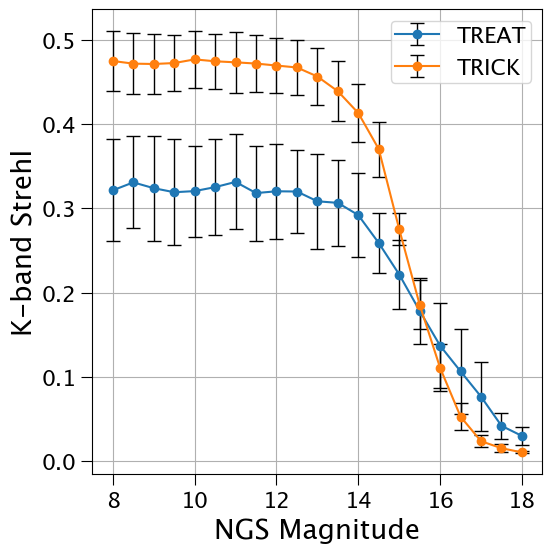

In [19]:
plt.errorbar(sorted_treat_ngs_mags, treat_k_band_strehl_mean, marker='o', yerr=treat_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_k_band_strehl_mean, marker='o', yerr=trick_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band Strehl')
plt.grid()
plt.legend()
plt.show()

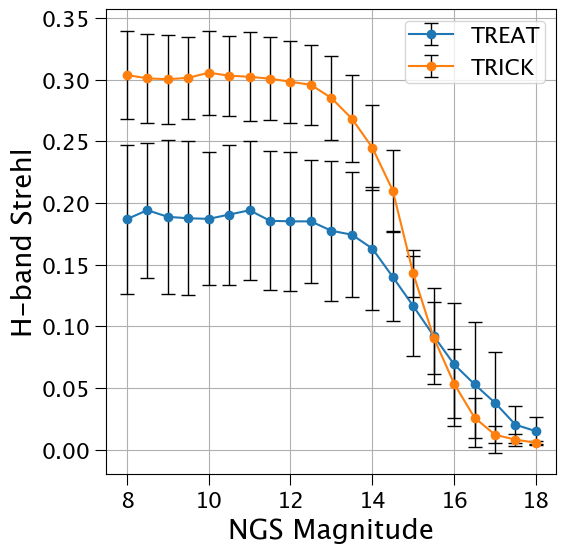

In [20]:
plt.errorbar(sorted_treat_ngs_mags, treat_h_band_strehl_mean, marker='o', yerr=treat_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_h_band_strehl_mean, marker='o', yerr=trick_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('H-band Strehl')
plt.grid()
plt.legend()
plt.show()

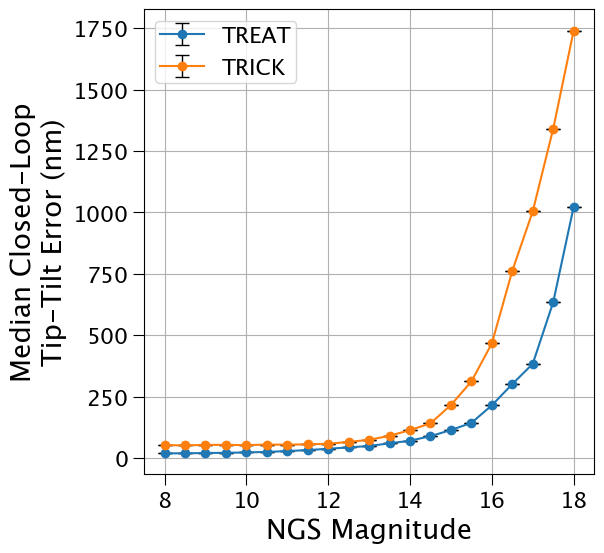

In [21]:
# Look at tip-tilt error as a function of NGS magnitude
plt.errorbar(sorted_treat_ngs_mags, treat_median_tt_error_mean, marker='o', yerr=treat_median_tt_error_std, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_median_tt_error_mean, marker='o', yerr=trick_median_tt_error_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed-Loop\nTip-Tilt Error (nm)')
plt.grid()
plt.legend()
plt.show()

## Same but for lower frame rate TREAT runs with fewer seeds

In [22]:
treat_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/')
result = get_sorted_values(treat_output_directory, run_num=5, seed=1)
sorted_slow_treat_ngs_mags, sorted_slow_treat_j_band_strehl, sorted_slow_treat_h_band_strehl, sorted_slow_treat_k_band_strehl, sorted_slow_treat_j_band_fwhm_e, sorted_slow_treat_h_band_fwhm_e, sorted_slow_treat_k_band_fwhm_e, sorted_slow_treat_errors = result
sorted_slow_treat_median_tt_error = sorted_slow_treat_errors["median_tt_error"]

# Get rid of the first result of all of them which was a bad run (wrong params)
sorted_slow_treat_ngs_mags = sorted_slow_treat_ngs_mags[1:]
sorted_slow_treat_j_band_strehl = sorted_slow_treat_j_band_strehl[1:]
sorted_slow_treat_h_band_strehl = sorted_slow_treat_h_band_strehl[1:]
sorted_slow_treat_k_band_strehl = sorted_slow_treat_k_band_strehl[1:]
sorted_slow_treat_j_band_fwhm_e = sorted_slow_treat_j_band_fwhm_e[1:]
sorted_slow_treat_h_band_fwhm_e = sorted_slow_treat_h_band_fwhm_e[1:]
sorted_slow_treat_k_band_fwhm_e = sorted_slow_treat_k_band_fwhm_e[1:]
sorted_slow_treat_median_tt_error = sorted_slow_treat_median_tt_error[1:]

Found 12 run files for run_num=5
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_11.0_run5_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  11.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_11.0_run5_small_1000Hz/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_18.0_run5_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  18.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_18.0_run5_small_1000Hz/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_14.0_run5_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  14.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/out

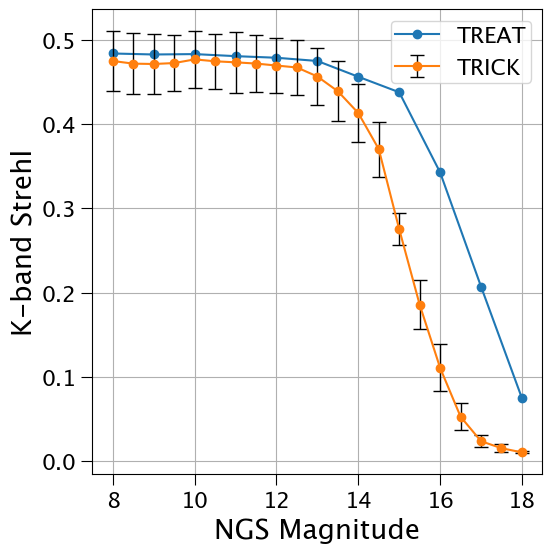

In [23]:
# plt.errorbar(sorted_treat_ngs_mags, treat_k_band_strehl_mean, marker='o', yerr=treat_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_k_band_strehl, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_k_band_strehl_mean, marker='o', yerr=trick_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band Strehl')
plt.grid()
plt.legend()
plt.show()

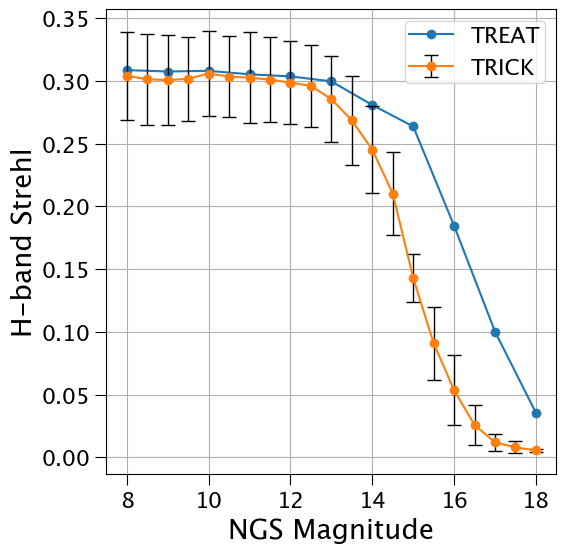

In [24]:
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_h_band_strehl, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_h_band_strehl_mean, marker='o', yerr=trick_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('H-band Strehl')
plt.grid()
plt.legend()
plt.show()

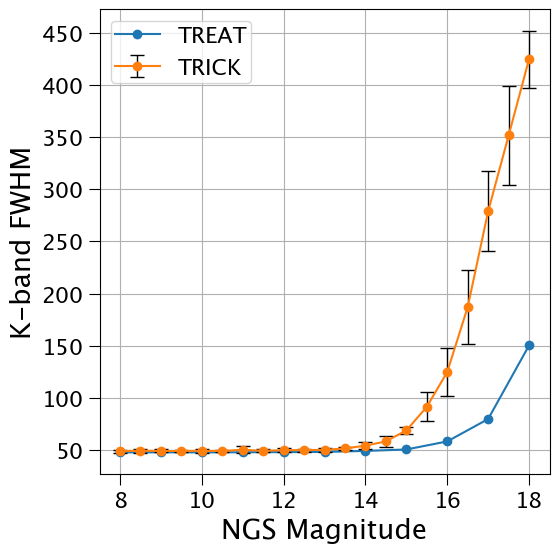

In [25]:
# Same but for FWHMs
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_k_band_fwhm_e, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_k_band_fwhm_e_mean, marker='o', yerr=trick_k_band_fwhm_e_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band FWHM')
plt.grid()
plt.legend()
plt.show()

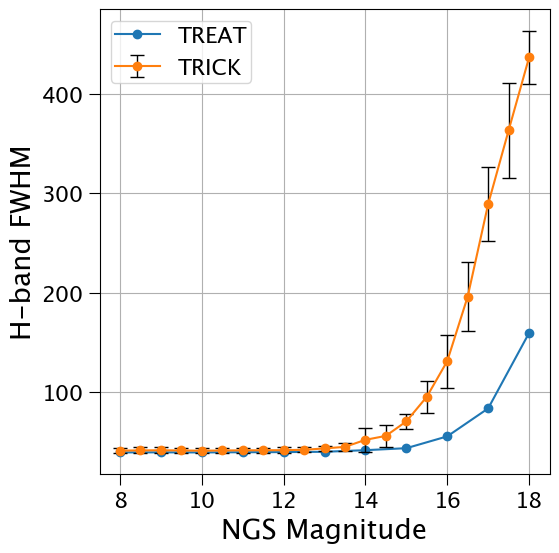

In [26]:
# Same but for FWHMs
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_h_band_fwhm_e, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_h_band_fwhm_e_mean, marker='o', yerr=trick_h_band_fwhm_e_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('H-band FWHM')
plt.grid()
plt.legend()
plt.show()

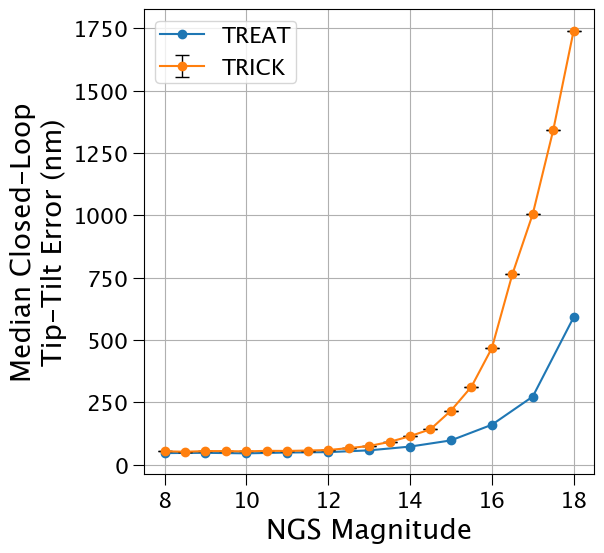

In [27]:
# Look at tip-tilt error as a function of NGS magnitude
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_median_tt_error, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_median_tt_error_mean, marker='o', yerr=trick_median_tt_error_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed-Loop\nTip-Tilt Error (nm)')
plt.grid()
plt.legend()
plt.show()

In [28]:
# Compare other values between TRICK & TREAT_1kHz
# sorted_errors = {
#         "median_total_ol_error": sorted_median_total_ol_error,
#         "median_total_error": sorted_median_total_error,
#         "median_tt_error": sorted_median_tt_error,
#         "median_ho_error": sorted_median_ho_error,
#         "median_lgs_error": sorted_median_lgs_error,
#         "median_ngs_tt_error": sorted_median_ngs_tt_error,
#         "median_ngs_total_error": sorted_median_ngs_total_error
#     }

# Get values from TREAT_1kHz slow run
sorted_slow_treat_median_total_ol_error = sorted_slow_treat_errors["median_total_ol_error"]
sorted_slow_treat_median_total_error = sorted_slow_treat_errors["median_total_error"]
sorted_slow_treat_median_tt_error = sorted_slow_treat_errors["median_tt_error"] # Already got this one
sorted_slow_treat_median_ho_error = sorted_slow_treat_errors["median_ho_error"]
sorted_slow_treat_median_lgs_error = sorted_slow_treat_errors["median_lgs_error"]
sorted_slow_treat_median_ngs_tt_error = sorted_slow_treat_errors["median_ngs_tt_error"]
sorted_slow_treat_median_ngs_total_error = sorted_slow_treat_errors["median_ngs_total_error"]

sorted_slow_treat_median_total_ol_error = sorted_slow_treat_median_total_ol_error[1:]
sorted_slow_treat_median_total_error = sorted_slow_treat_median_total_error[1:]
sorted_slow_treat_median_tt_error = sorted_slow_treat_median_tt_error[1:]
sorted_slow_treat_median_ho_error = sorted_slow_treat_median_ho_error[1:]
sorted_slow_treat_median_lgs_error = sorted_slow_treat_median_lgs_error[1:]
sorted_slow_treat_median_ngs_tt_error = sorted_slow_treat_median_ngs_tt_error[1:]
sorted_slow_treat_median_ngs_total_error = sorted_slow_treat_median_ngs_total_error[1:]

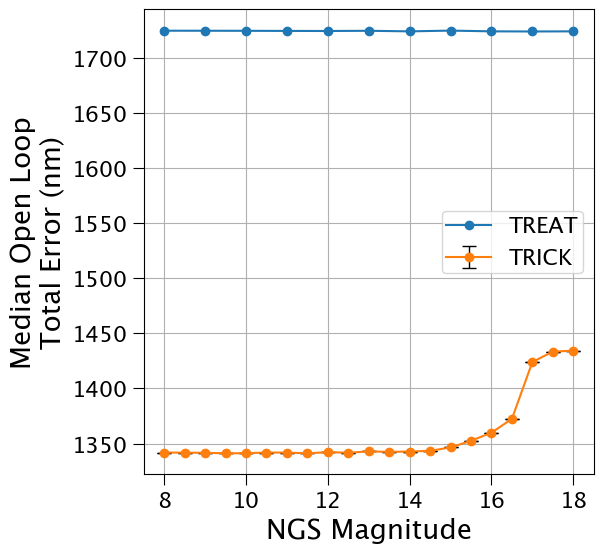

In [29]:
# Do total OL error
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_median_total_ol_error, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_median_total_ol_error_mean, marker='o', yerr=trick_median_total_ol_error_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Open Loop\nTotal Error (nm)')
plt.grid()
plt.legend()
plt.show()

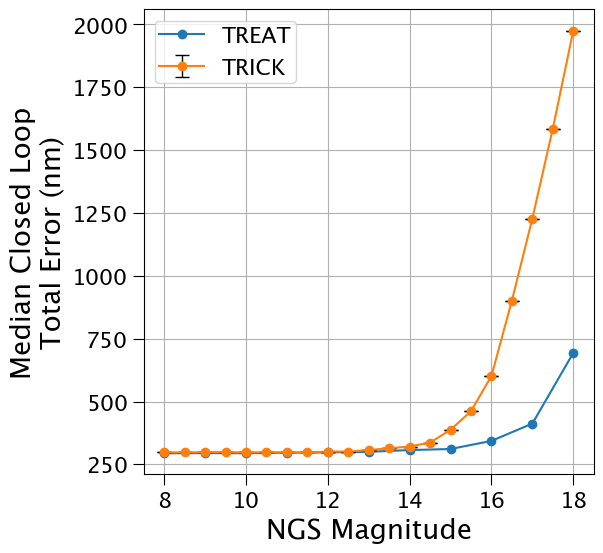

In [30]:
# Do total error
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_median_total_error, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_median_total_error_mean, marker='o', yerr=trick_median_total_error_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed Loop\nTotal Error (nm)')
plt.grid()
plt.legend()
plt.show()

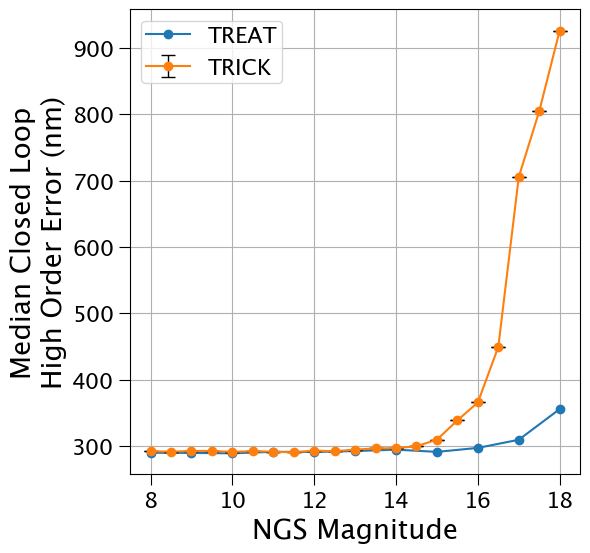

In [31]:
# Do total high order closed loop error
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_median_ho_error, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_median_ho_error_mean, marker='o', yerr=trick_median_ho_error_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed Loop\nHigh Order Error (nm)')
plt.grid()
plt.legend()
plt.show()

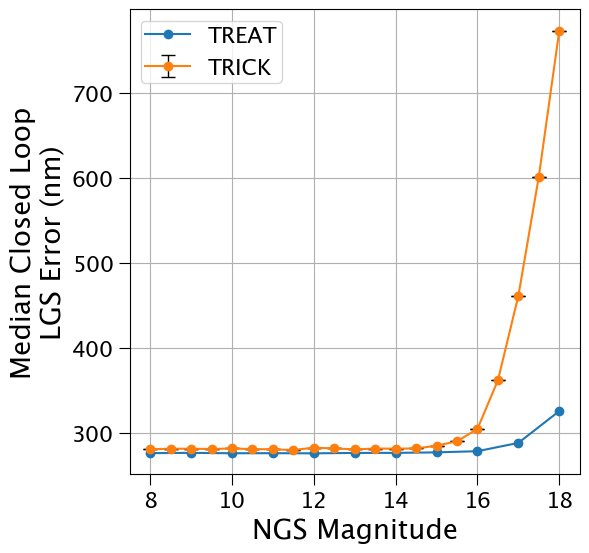

In [32]:
# Do total LGS closed loop error
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_median_lgs_error, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_median_lgs_error_mean, marker='o', yerr=trick_median_lgs_error_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed Loop\nLGS Error (nm)')
plt.grid()
plt.legend()
plt.show()

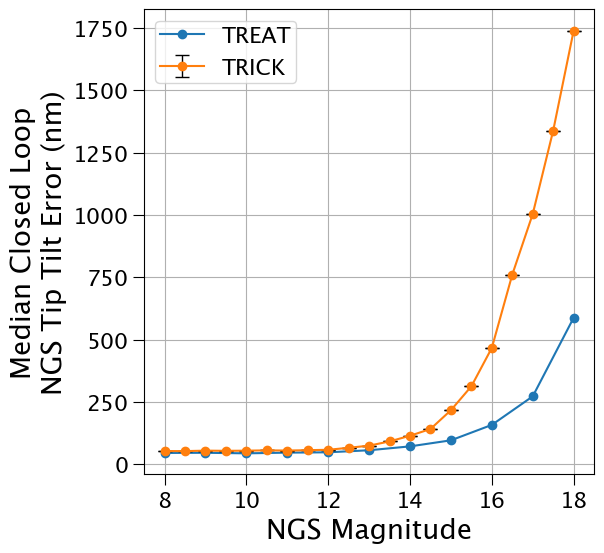

In [33]:
# Do total NGS tip tilt closed loop error
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_median_ngs_tt_error, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_median_ngs_tt_error_mean, marker='o', yerr=trick_median_ngs_tt_error_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed Loop\nNGS Tip Tilt Error (nm)')
plt.grid()
plt.legend()
plt.show()

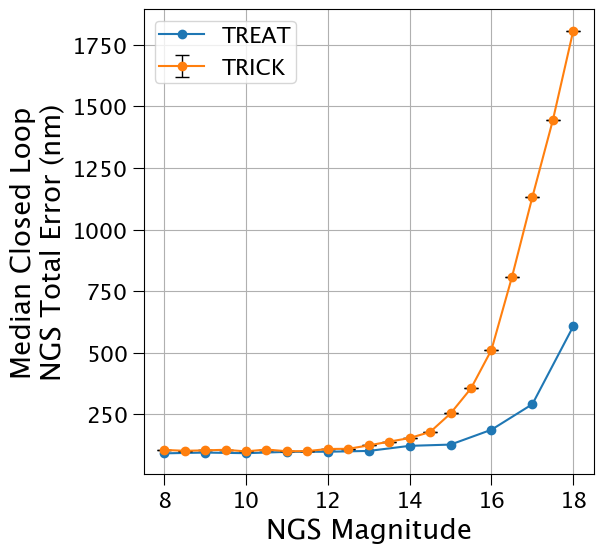

In [34]:
# Do total NGS total closed loop error
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_median_ngs_total_error, marker='o', label="TREAT")
plt.errorbar(sorted_trick_ngs_mags, trick_median_ngs_total_error_mean, marker='o', yerr=trick_median_ngs_total_error_std, capsize=5, elinewidth=1, ecolor='black', label="TRICK")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed Loop\nNGS Total Error (nm)')
plt.grid()
plt.legend()
plt.show()

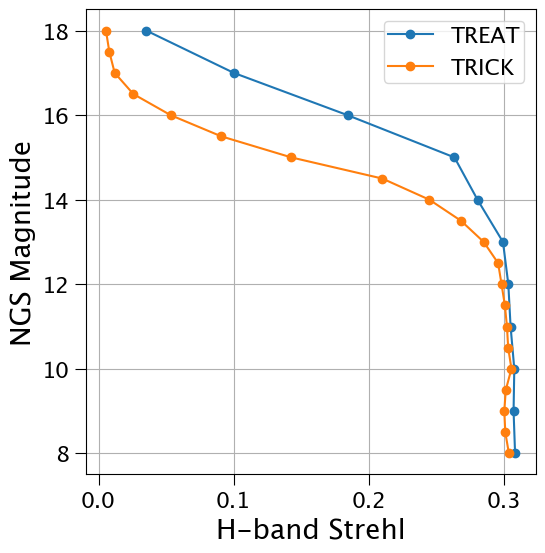

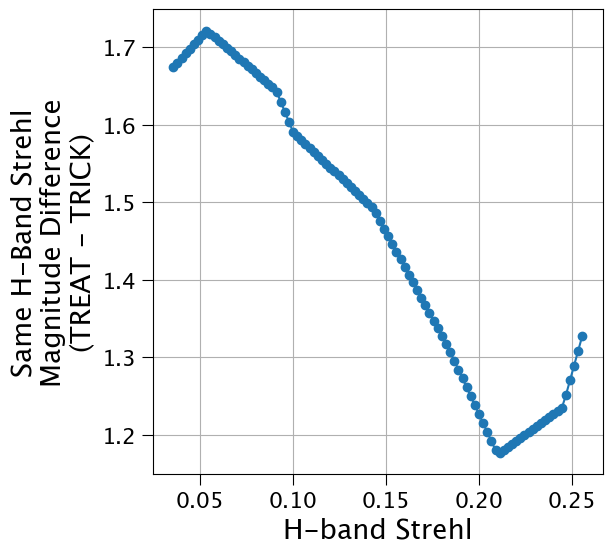

In [35]:
# Let's do a comparison to see how many mags better TREAT Is than TRICK
# To do this we'll use H-band Strehl. We basically want the horizontal distance between the curves
# ie at a given H band Strehl, how much better in terms of NGS magnitude is TREAT than TRICK
# We'll do this by interpolating the curves and then finding the difference in mags at a given Strehl value

# Import useful interpolation function
from scipy.interpolate import interp1d

# Create interpolation functions for both TRICK and TREAT
treat_interp_func = interp1d(sorted_slow_treat_h_band_strehl, sorted_slow_treat_ngs_mags, kind='linear', fill_value='extrapolate')
trick_interp_func = interp1d(trick_h_band_strehl_mean, sorted_trick_ngs_mags, kind='linear', fill_value='extrapolate')

# Make a plot to visualize the interpolation
plt.plot(sorted_slow_treat_h_band_strehl, treat_interp_func(sorted_slow_treat_h_band_strehl), marker='o', label="TREAT")
plt.plot(trick_h_band_strehl_mean, trick_interp_func(trick_h_band_strehl_mean), marker='o', label="TRICK")
plt.xlabel('H-band Strehl')
plt.ylabel('NGS Magnitude')
plt.grid()
plt.legend()
plt.show()

# Subtract the TRICK mags from the TREAT mags at a given Strehl to see how many mags better TREAT is
def calculate_mag_difference_at_strehl(strehl_value):
    treat_mag_at_strehl = treat_interp_func(strehl_value)
    trick_mag_at_strehl = trick_interp_func(strehl_value)
    mag_difference = treat_mag_at_strehl - trick_mag_at_strehl
    return mag_difference

# Make this plot for the sorted_slow_treat_ngs_mags
strehl_values_to_check = np.linspace(min(sorted_slow_treat_h_band_strehl), max(trick_h_band_strehl_mean) - 0.05, 100)
mag_differences = [calculate_mag_difference_at_strehl(s) for s in strehl_values_to_check]

plt.plot(strehl_values_to_check, mag_differences, marker='o')
plt.xlabel('H-band Strehl')
plt.ylabel('Same H-Band Strehl\nMagnitude Difference\n(TREAT - TRICK)')
plt.grid()
plt.show()

## Short 1kHz TREAT sims with H-band light going to WFS

In [36]:
treat_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/')
result = get_sorted_values(treat_output_directory, run_num=1, seed=1)
sorted_slow_treat_H_ngs_mags, sorted_slow_treat_H_j_band_strehl, sorted_slow_treat_H_h_band_strehl, sorted_slow_treat_H_k_band_strehl, sorted_slow_treat_H_j_band_fwhm_e, sorted_slow_treat_H_h_band_fwhm_e, sorted_slow_treat_H_k_band_fwhm_e, sorted_slow_treat_H_errors = result
sorted_slow_treat_H_median_tt_error = sorted_slow_treat_H_errors["median_tt_error"]

# Get rid of the first result of all of them which was a bad run (wrong params)
sorted_slow_treat_H_ngs_mags = sorted_slow_treat_H_ngs_mags
sorted_slow_treat_H_j_band_strehl = sorted_slow_treat_H_j_band_strehl
sorted_slow_treat_H_h_band_strehl = sorted_slow_treat_H_h_band_strehl
sorted_slow_treat_H_k_band_strehl = sorted_slow_treat_H_k_band_strehl
sorted_slow_treat_H_j_band_fwhm_e = sorted_slow_treat_H_j_band_fwhm_e
sorted_slow_treat_H_h_band_fwhm_e = sorted_slow_treat_H_h_band_fwhm_e
sorted_slow_treat_H_k_band_fwhm_e = sorted_slow_treat_H_k_band_fwhm_e
sorted_slow_treat_H_median_tt_error = sorted_slow_treat_H_median_tt_error

Found 11 run files for run_num=1
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_10.0_run1_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  10.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_10.0_run1_small_1000Hz/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_18.0_run1_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  18.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_18.0_run1_small_1000Hz/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_8.0_run1_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  8.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/T

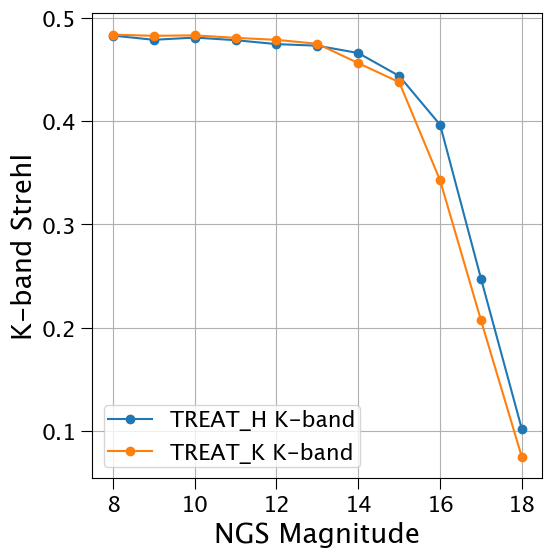

In [37]:
# Look at TREAT_H in H-band vs. TREAT_K in H-band
plt.plot(sorted_slow_treat_H_ngs_mags, sorted_slow_treat_H_k_band_strehl, marker='o', label="TREAT_H K-band") # Treat_H in K band
plt.plot(sorted_slow_treat_ngs_mags, sorted_slow_treat_k_band_strehl, marker='o', label="TREAT_K K-band") # Treat_K in K band
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band Strehl')
plt.grid()
plt.legend()
plt.show()

## TRICK-H

In [39]:
trick_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/')
result = get_sorted_values(trick_output_directory, run_num=2, seed=1)
sorted_trick_H_ngs_mags, sorted_trick_H_j_band_strehl, sorted_trick_H_h_band_strehl, sorted_trick_H_k_band_strehl, sorted_trick_H_j_band_fwhm_e, sorted_trick_H_h_band_fwhm_e, sorted_trick_H_k_band_fwhm_e, sorted_trick_H_errors = result
sorted_trick_H_median_tt_error = sorted_trick_H_errors["median_tt_error"]

Found 11 run files for run_num=2
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_8.0_run2/
TRICK LATER RUN 
Found NGS magnitude:  8.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_8.0_run2/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_13.0_run2/
TRICK LATER RUN 
Found NGS magnitude:  13.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_13.0_run2/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_9.0_run2/
TRICK LATER RUN 
Found NGS magnitude:  9.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_9.0_run2/ for simulation results.

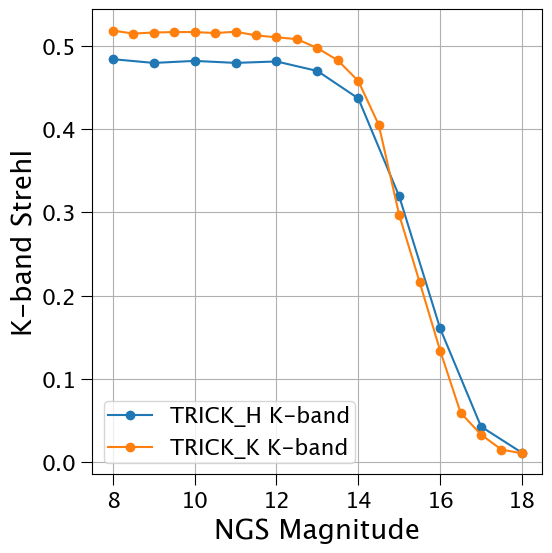

In [40]:
# Look at TRICK_K in H-band vs. TRICK_H in H-band
plt.plot(sorted_trick_H_ngs_mags, sorted_trick_H_k_band_strehl, marker='o', label="TRICK_H K-band") # TRICK_H in K band
plt.plot(sorted_trick_ngs_mags, sorted_trick_k_band_strehl, marker='o', label="TRICK_K K-band") # TRICK_K in K band (basic TRICK so we don't say TRICK_K)
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band Strehl')
plt.grid()
plt.legend()
plt.show()

## TRICK-H vs. TREAT-H

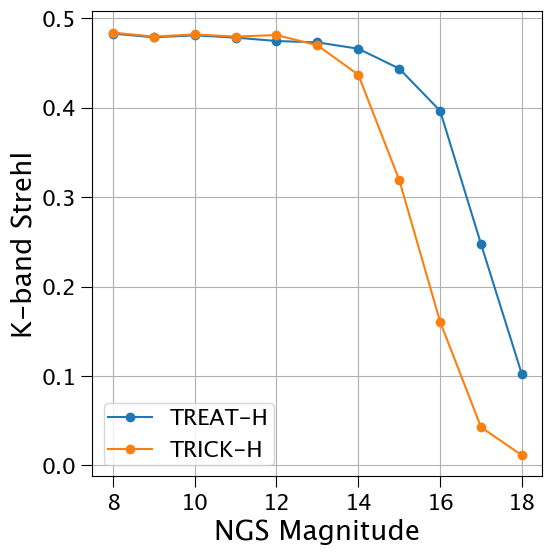

In [41]:
# plt.errorbar(sorted_treat_ngs_mags, treat_k_band_strehl_mean, marker='o', yerr=treat_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.plot(sorted_slow_treat_H_ngs_mags, sorted_slow_treat_H_k_band_strehl, marker='o', label="TREAT-H")
plt.plot(sorted_trick_H_ngs_mags, sorted_trick_H_k_band_strehl, marker='o',label="TRICK-H")
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band Strehl')
plt.grid()
plt.legend()
plt.show()

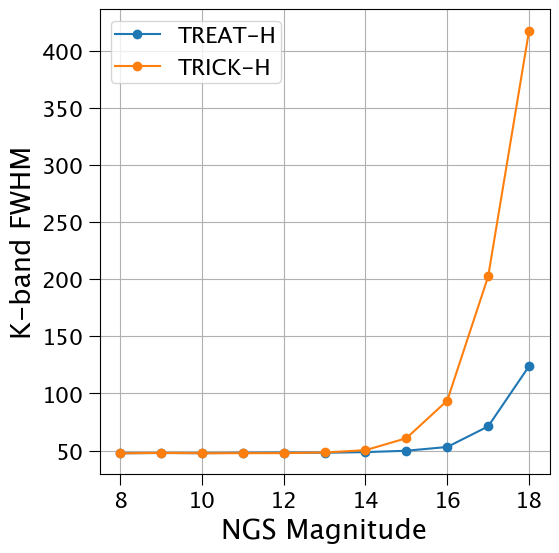

In [42]:
# plt.errorbar(sorted_treat_ngs_mags, treat_k_band_strehl_mean, marker='o', yerr=treat_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.plot(sorted_slow_treat_H_ngs_mags, sorted_slow_treat_H_k_band_fwhm_e, marker='o', label="TREAT-H")
plt.plot(sorted_trick_H_ngs_mags, sorted_trick_H_k_band_fwhm_e, marker='o',label="TRICK-H")
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band FWHM')
plt.grid()
plt.legend()
plt.show()

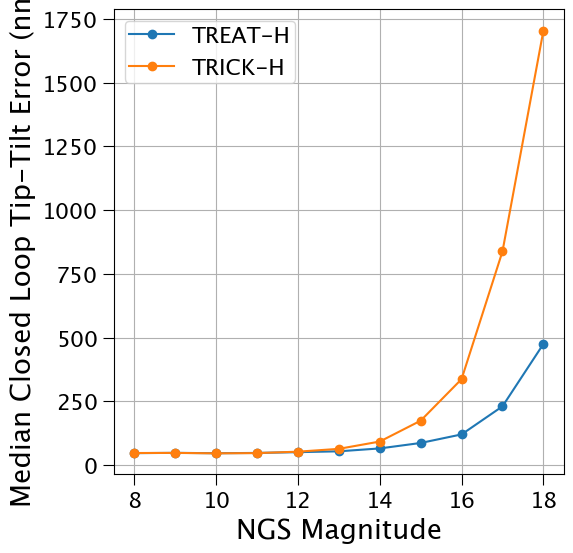

In [43]:
plt.plot(sorted_slow_treat_H_ngs_mags, sorted_slow_treat_H_median_tt_error, marker='o', label="TREAT-H")
plt.plot(sorted_trick_H_ngs_mags, sorted_trick_H_median_tt_error, marker='o',label="TRICK-H")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed Loop Tip-Tilt Error (nm)')
plt.grid()
plt.legend()
plt.show()

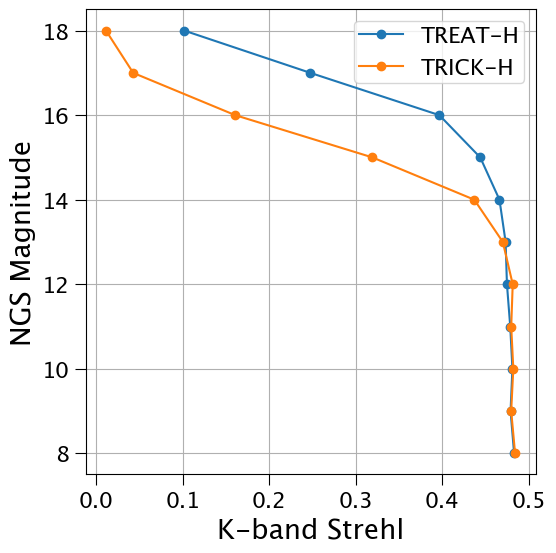

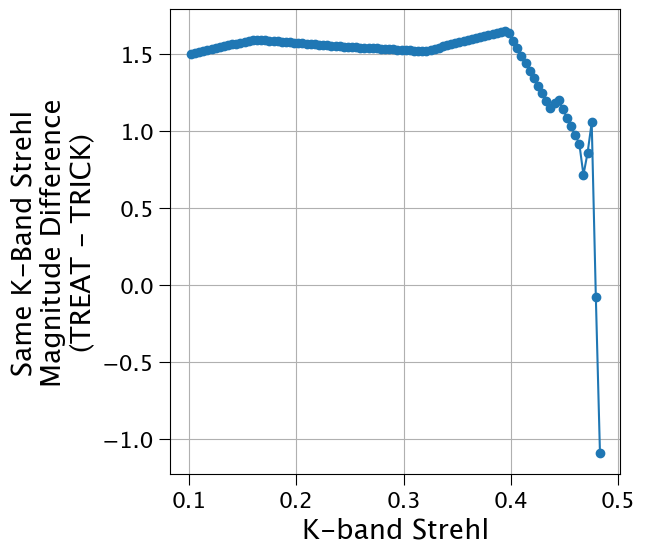

In [44]:
from scipy.interpolate import interp1d

# Create interpolation functions for both TRICK and TREAT using K-band data
# Note: interp1d needs x-values (Strehl) to be the independent variable,
# so we swap axes compared to the original plot (which had mags on x-axis)
treat_interp_func = interp1d(sorted_slow_treat_H_k_band_strehl, sorted_slow_treat_H_ngs_mags, kind='linear', fill_value='extrapolate')
trick_interp_func = interp1d(sorted_trick_H_k_band_strehl, sorted_trick_H_ngs_mags, kind='linear', fill_value='extrapolate')

# Make a plot to visualize the interpolation
plt.plot(sorted_slow_treat_H_k_band_strehl, treat_interp_func(sorted_slow_treat_H_k_band_strehl), marker='o', label="TREAT-H")
plt.plot(sorted_trick_H_k_band_strehl, trick_interp_func(sorted_trick_H_k_band_strehl), marker='o', label="TRICK-H")
plt.xlabel('K-band Strehl')
plt.ylabel('NGS Magnitude')
plt.grid()
plt.legend()
plt.show()

# Subtract the TRICK mags from the TREAT mags at a given Strehl
def calculate_mag_difference_at_strehl(strehl_value):
    treat_mag_at_strehl = treat_interp_func(strehl_value)
    trick_mag_at_strehl = trick_interp_func(strehl_value)
    mag_difference = treat_mag_at_strehl - trick_mag_at_strehl
    return mag_difference

# Evaluate over the overlapping Strehl range to avoid extrapolation artifacts
strehl_min = max(min(sorted_slow_treat_H_k_band_strehl), min(sorted_trick_H_k_band_strehl))
strehl_max = min(max(sorted_slow_treat_H_k_band_strehl), max(sorted_trick_H_k_band_strehl))
strehl_values_to_check = np.linspace(strehl_min, strehl_max, 100)

mag_differences = [calculate_mag_difference_at_strehl(s) for s in strehl_values_to_check]

plt.plot(strehl_values_to_check, mag_differences, marker='o')
plt.xlabel('K-band Strehl')
plt.ylabel('Same K-Band Strehl\nMagnitude Difference\n(TREAT - TRICK)')
plt.grid()
plt.show()

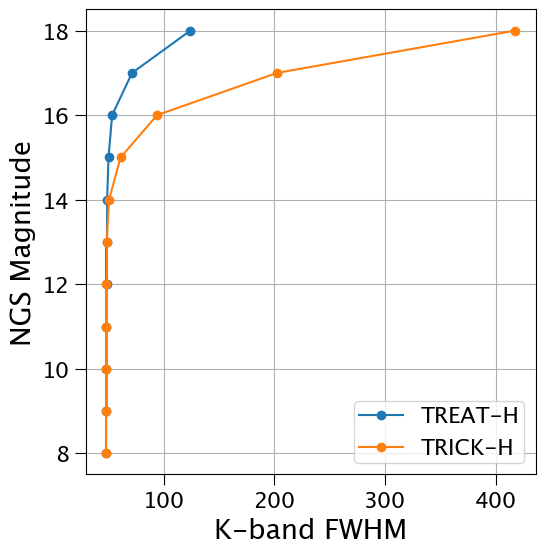

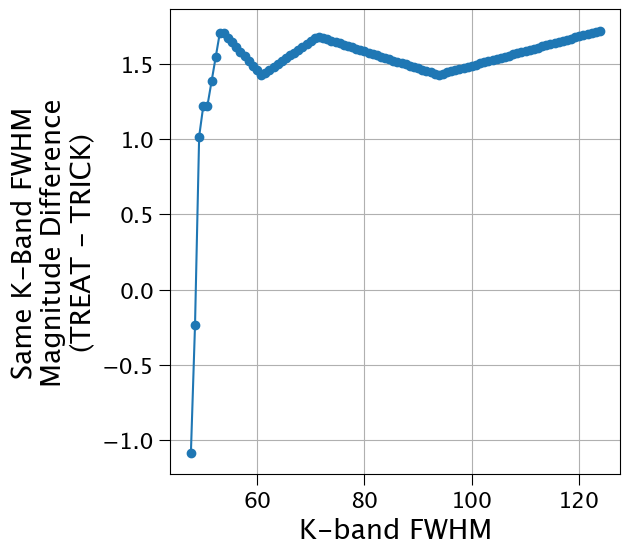

In [45]:
from scipy.interpolate import interp1d

# Create interpolation functions using FWHM as the independent variable
# We want: at a given FWHM, what NGS mag can TREAT vs TRICK achieve?
# Note: FWHM is inverted relative to Strehl — lower is better — so we sort accordingly
treat_fwhm_sorted_idx = np.argsort(sorted_slow_treat_H_k_band_fwhm_e)
trick_fwhm_sorted_idx = np.argsort(sorted_trick_H_k_band_fwhm_e)

treat_fwhm_sorted = np.array(sorted_slow_treat_H_k_band_fwhm_e)[treat_fwhm_sorted_idx]
treat_mags_sorted = np.array(sorted_slow_treat_H_ngs_mags)[treat_fwhm_sorted_idx]

trick_fwhm_sorted = np.array(sorted_trick_H_k_band_fwhm_e)[trick_fwhm_sorted_idx]
trick_mags_sorted = np.array(sorted_trick_H_ngs_mags)[trick_fwhm_sorted_idx]

treat_interp_func = interp1d(treat_fwhm_sorted, treat_mags_sorted, kind='linear', fill_value='extrapolate')
trick_interp_func = interp1d(trick_fwhm_sorted, trick_mags_sorted, kind='linear', fill_value='extrapolate')

# Visualize the interpolation
plt.plot(treat_fwhm_sorted, treat_interp_func(treat_fwhm_sorted), marker='o', label="TREAT-H")
plt.plot(trick_fwhm_sorted, trick_interp_func(trick_fwhm_sorted), marker='o', label="TRICK-H")
plt.xlabel('K-band FWHM')
plt.ylabel('NGS Magnitude')
plt.grid()
plt.legend()
plt.show()

# At a given FWHM, how many mags better is TREAT than TRICK?
def calculate_mag_difference_at_fwhm(fwhm_value):
    treat_mag_at_fwhm = treat_interp_func(fwhm_value)
    trick_mag_at_fwhm = trick_interp_func(fwhm_value)
    return treat_mag_at_fwhm - trick_mag_at_fwhm

# Evaluate over the overlapping FWHM range
fwhm_min = max(min(treat_fwhm_sorted), min(trick_fwhm_sorted))
fwhm_max = min(max(treat_fwhm_sorted), max(trick_fwhm_sorted))
fwhm_values_to_check = np.linspace(fwhm_min, fwhm_max, 100)

mag_differences = [calculate_mag_difference_at_fwhm(f) for f in fwhm_values_to_check]

plt.plot(fwhm_values_to_check, mag_differences, marker='o')
plt.xlabel('K-band FWHM')
plt.ylabel('Same K-Band FWHM\nMagnitude Difference\n(TREAT - TRICK)')
plt.grid()
plt.show()

## TRICK in H band vs. TREAT in H band with new SLGS signal level values

We're going to compare TRICK_H run3 with TREAT_H run 2. The difference here is the signal level goes down from 600 e-/subap/fr at 500Hz to ~370 based on new telemetry analysis of what's actually going on on sky

In [46]:
treat_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/')
result = get_sorted_values(treat_output_directory, run_num=2, seed=1)
sorted_slow_treat_H_ngs_mags_new, sorted_slow_treat_H_j_band_strehl_new, sorted_slow_treat_H_h_band_strehl_new, sorted_slow_treat_H_k_band_strehl_new, sorted_slow_treat_H_j_band_fwhm_e_new, sorted_slow_treat_H_h_band_fwhm_e_new, sorted_slow_treat_H_k_band_fwhm_e_new, sorted_slow_treat_H_errors_new = result
sorted_slow_treat_H_median_tt_error_new = sorted_slow_treat_H_errors_new["median_tt_error"]

Found 11 run files for run_num=2
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_11.0_run2_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  11.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_11.0_run2_small_1000Hz/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_15.0_run2_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  15.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_15.0_run2_small_1000Hz/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT_H/outputs/A_comparison_tt_mag_12.0_run2_small_1000Hz/
TREAT LATER RUN 
Found NGS magnitude:  12.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT

In [62]:
trick_output_directory = Path(f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/')
result = get_sorted_values(trick_output_directory, run_num=3, seed=1)
sorted_trick_H_ngs_mags_new, sorted_trick_H_j_band_strehl_new, sorted_trick_H_h_band_strehl_new, sorted_trick_H_k_band_strehl_new, sorted_trick_H_j_band_fwhm_e_new, sorted_trick_H_h_band_fwhm_e_new, sorted_trick_H_k_band_fwhm_e_new, sorted_trick_H_errors_new = result
sorted_trick_H_median_tt_error_new = sorted_trick_H_errors_new["median_tt_error"]

Found 11 run files for run_num=3
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_13.0_run3/
TRICK LATER RUN 
Found NGS magnitude:  13.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_13.0_run3/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_11.0_run3/
TRICK LATER RUN 
Found NGS magnitude:  11.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_11.0_run3/ for simulation results...
xx =  0.0 yy =  0.0
Processing directory:  /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_9.0_run3/
TRICK LATER RUN 
Found NGS magnitude:  9.0
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_H/outputs/A_comparison_tt_mag_9.0_run3/ for simulation resul

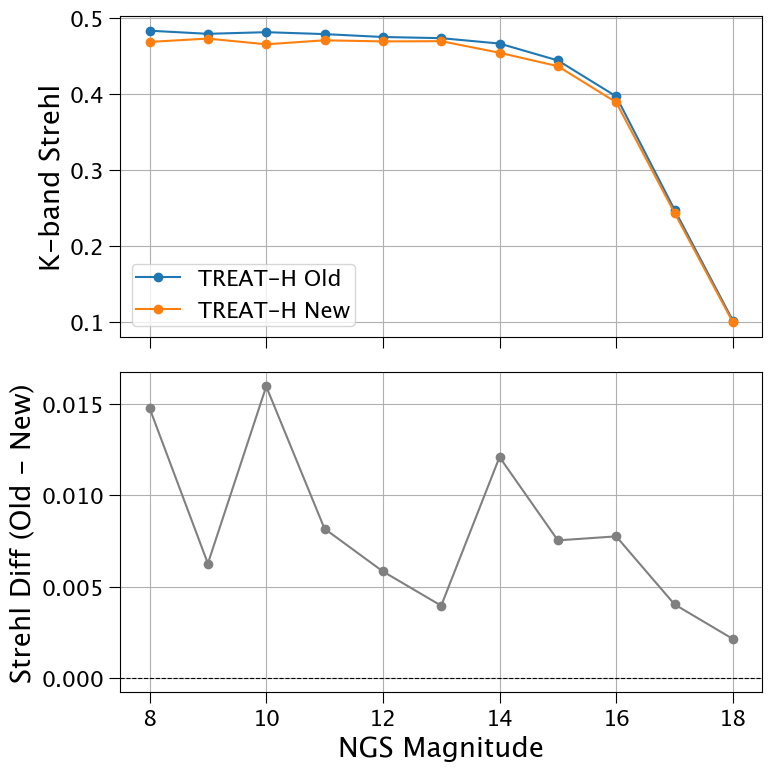

In [63]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

ax1.plot(sorted_slow_treat_H_ngs_mags, sorted_slow_treat_H_k_band_strehl, marker='o', label="TREAT-H Old")
ax1.plot(sorted_slow_treat_H_ngs_mags_new, sorted_slow_treat_H_k_band_strehl_new, marker='o', label="TREAT-H New")
ax1.set_ylabel('K-band Strehl')
ax1.grid()
ax1.legend()

# Subtract the two: old - new
strehl_diff = np.array(sorted_slow_treat_H_k_band_strehl) - np.array(sorted_slow_treat_H_k_band_strehl_new)

ax2.plot(sorted_slow_treat_H_ngs_mags_new, strehl_diff, marker='o', color='gray')
ax2.axhline(0, color='k', linestyle='--', linewidth=0.8)
ax2.set_xlabel('NGS Magnitude')
ax2.set_ylabel('Strehl Diff (Old - New)')
ax2.grid()

plt.tight_layout()
plt.show()


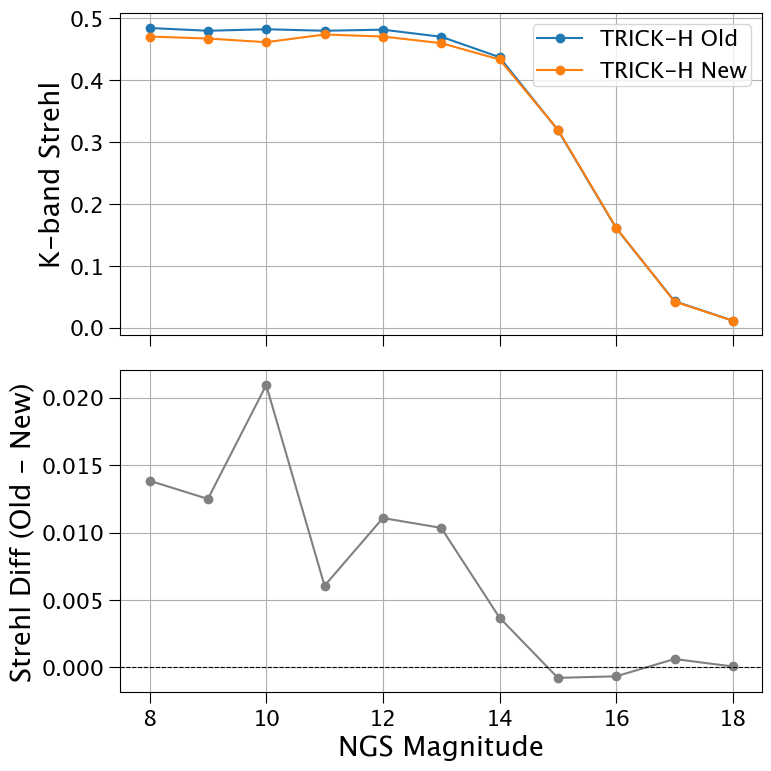

In [64]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

ax1.plot(sorted_trick_H_ngs_mags, sorted_trick_H_k_band_strehl, marker='o', label="TRICK-H Old")
ax1.plot(sorted_trick_H_ngs_mags_new, sorted_trick_H_k_band_strehl_new, marker='o', label="TRICK-H New")
ax1.set_ylabel('K-band Strehl')
ax1.grid()
ax1.legend()

# Subtract the two: old - new
strehl_diff = np.array(sorted_trick_H_k_band_strehl) - np.array(sorted_trick_H_k_band_strehl_new)

ax2.plot(sorted_trick_H_ngs_mags_new, strehl_diff, marker='o', color='gray')
ax2.axhline(0, color='k', linestyle='--', linewidth=0.8)
ax2.set_xlabel('NGS Magnitude')
ax2.set_ylabel('Strehl Diff (Old - New)')
ax2.grid()

plt.tight_layout()
plt.show()


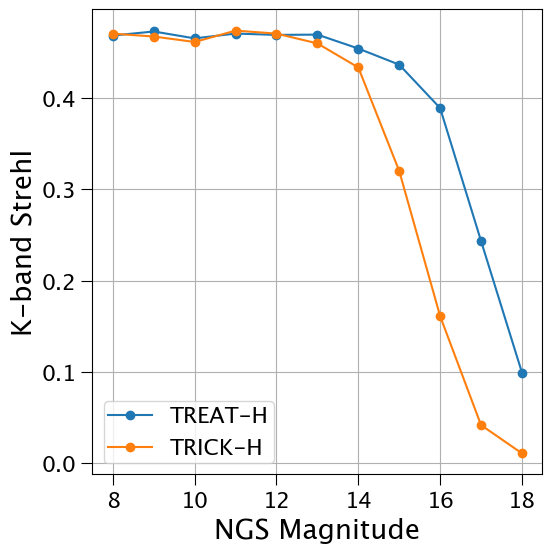

In [65]:
# plt.errorbar(sorted_treat_ngs_mags, treat_k_band_strehl_mean, marker='o', yerr=treat_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.plot(sorted_slow_treat_H_ngs_mags_new, sorted_slow_treat_H_k_band_strehl_new, marker='o', label="TREAT-H")
plt.plot(sorted_trick_H_ngs_mags_new, sorted_trick_H_k_band_strehl_new, marker='o',label="TRICK-H")
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band Strehl')
plt.grid()
plt.legend()
plt.show()

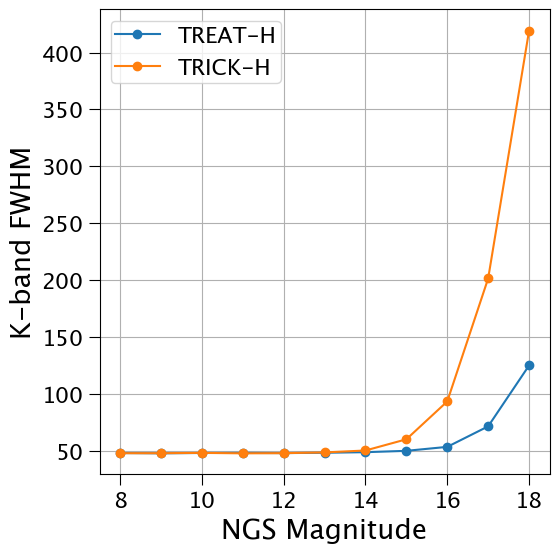

In [66]:
# plt.errorbar(sorted_treat_ngs_mags, treat_k_band_strehl_mean, marker='o', yerr=treat_k_band_strehl_std, capsize=5, elinewidth=1, ecolor='black', label="TREAT")
plt.plot(sorted_slow_treat_H_ngs_mags_new, sorted_slow_treat_H_k_band_fwhm_e_new, marker='o', label="TREAT-H")
plt.plot(sorted_trick_H_ngs_mags_new, sorted_trick_H_k_band_fwhm_e_new, marker='o',label="TRICK-H")
plt.xlabel('NGS Magnitude')
plt.ylabel('K-band FWHM')
plt.grid()
plt.legend()
plt.show()

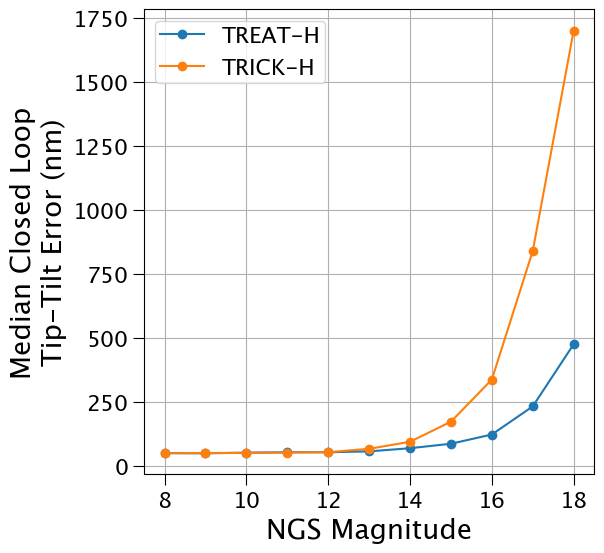

In [67]:
plt.plot(sorted_slow_treat_H_ngs_mags_new, sorted_slow_treat_H_median_tt_error_new, marker='o', label="TREAT-H")
plt.plot(sorted_trick_H_ngs_mags_new, sorted_trick_H_median_tt_error_new, marker='o',label="TRICK-H")
plt.xlabel('NGS Magnitude')
plt.ylabel('Median Closed Loop\nTip-Tilt Error (nm)')
plt.grid()
plt.legend()
plt.show()

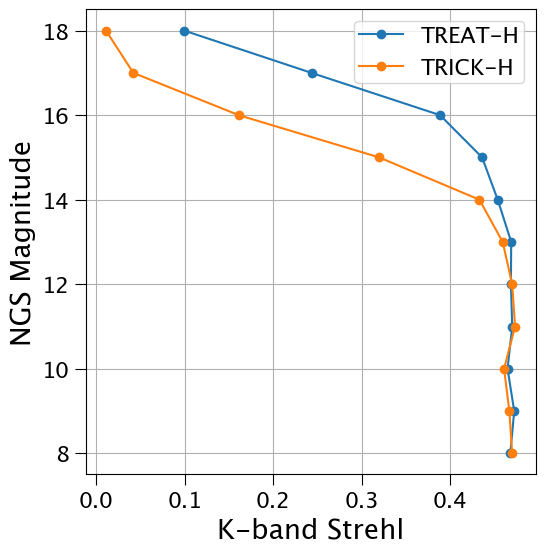

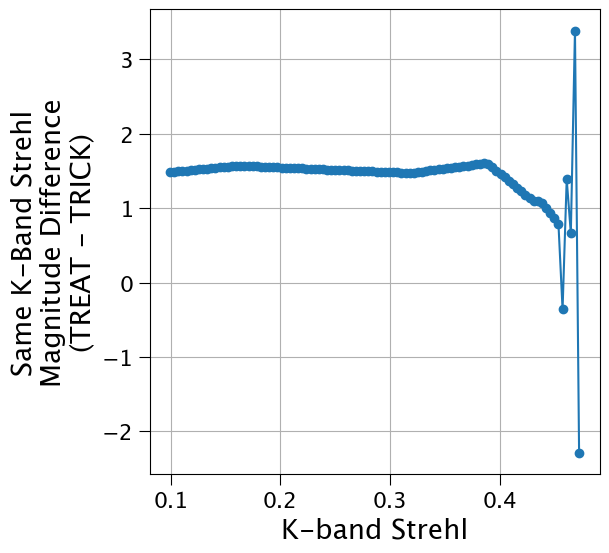

In [68]:
from scipy.interpolate import interp1d

# Create interpolation functions for both TRICK and TREAT using K-band data
# Note: interp1d needs x-values (Strehl) to be the independent variable,
# so we swap axes compared to the original plot (which had mags on x-axis)
treat_interp_func = interp1d(sorted_slow_treat_H_k_band_strehl_new, sorted_slow_treat_H_ngs_mags_new, kind='linear', fill_value='extrapolate')
trick_interp_func = interp1d(sorted_trick_H_k_band_strehl_new, sorted_trick_H_ngs_mags_new, kind='linear', fill_value='extrapolate')

# Make a plot to visualize the interpolation
plt.plot(sorted_slow_treat_H_k_band_strehl_new, treat_interp_func(sorted_slow_treat_H_k_band_strehl_new), marker='o', label="TREAT-H")
plt.plot(sorted_trick_H_k_band_strehl_new, trick_interp_func(sorted_trick_H_k_band_strehl_new), marker='o', label="TRICK-H")
plt.xlabel('K-band Strehl')
plt.ylabel('NGS Magnitude')
plt.grid()
plt.legend()
plt.show()

# Subtract the TRICK mags from the TREAT mags at a given Strehl
def calculate_mag_difference_at_strehl(strehl_value):
    treat_mag_at_strehl = treat_interp_func(strehl_value)
    trick_mag_at_strehl = trick_interp_func(strehl_value)
    mag_difference = treat_mag_at_strehl - trick_mag_at_strehl
    return mag_difference

# Evaluate over the overlapping Strehl range to avoid extrapolation artifacts
strehl_min = max(min(sorted_slow_treat_H_k_band_strehl_new), min(sorted_trick_H_k_band_strehl_new))
strehl_max = min(max(sorted_slow_treat_H_k_band_strehl_new), max(sorted_trick_H_k_band_strehl_new))
strehl_values_to_check = np.linspace(strehl_min, strehl_max, 100)

mag_differences = [calculate_mag_difference_at_strehl(s) for s in strehl_values_to_check]

plt.plot(strehl_values_to_check, mag_differences, marker='o')
plt.xlabel('K-band Strehl')
plt.ylabel('Same K-Band Strehl\nMagnitude Difference\n(TREAT - TRICK)')
plt.grid()
plt.show()

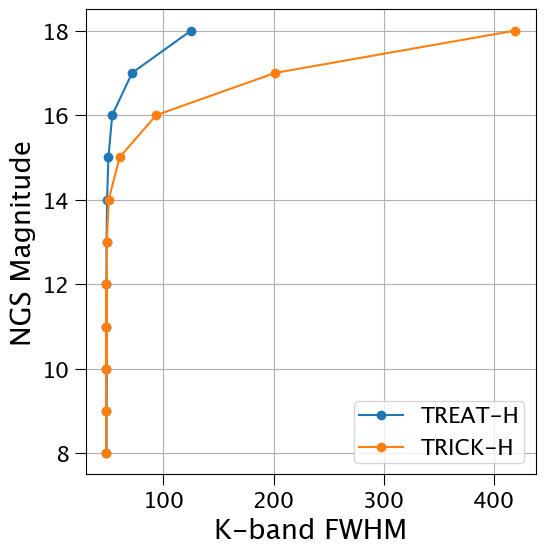

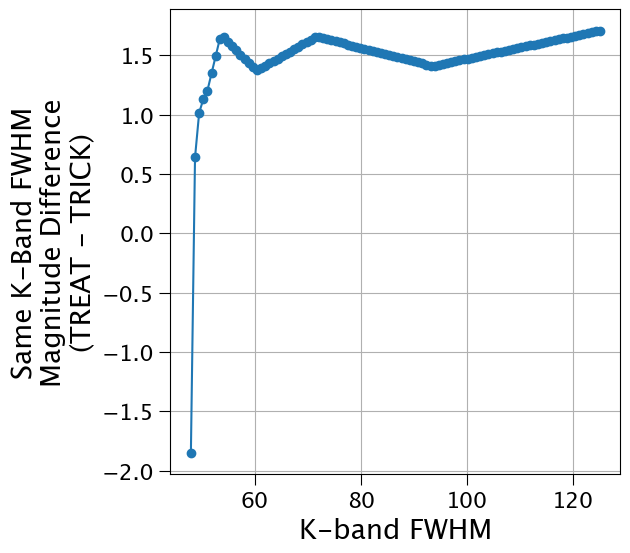

In [69]:
from scipy.interpolate import interp1d

# Create interpolation functions using FWHM as the independent variable
# We want: at a given FWHM, what NGS mag can TREAT vs TRICK achieve?
# Note: FWHM is inverted relative to Strehl — lower is better — so we sort accordingly
treat_fwhm_sorted_idx = np.argsort(sorted_slow_treat_H_k_band_fwhm_e_new)
trick_fwhm_sorted_idx = np.argsort(sorted_trick_H_k_band_fwhm_e_new)

treat_fwhm_sorted = np.array(sorted_slow_treat_H_k_band_fwhm_e_new)[treat_fwhm_sorted_idx]
treat_mags_sorted = np.array(sorted_slow_treat_H_ngs_mags_new)[treat_fwhm_sorted_idx]

trick_fwhm_sorted = np.array(sorted_trick_H_k_band_fwhm_e_new)[trick_fwhm_sorted_idx]
trick_mags_sorted = np.array(sorted_trick_H_ngs_mags_new)[trick_fwhm_sorted_idx]

treat_interp_func = interp1d(treat_fwhm_sorted, treat_mags_sorted, kind='linear', fill_value='extrapolate')
trick_interp_func = interp1d(trick_fwhm_sorted, trick_mags_sorted, kind='linear', fill_value='extrapolate')

# Visualize the interpolation
plt.plot(treat_fwhm_sorted, treat_interp_func(treat_fwhm_sorted), marker='o', label="TREAT-H")
plt.plot(trick_fwhm_sorted, trick_interp_func(trick_fwhm_sorted), marker='o', label="TRICK-H")
plt.xlabel('K-band FWHM')
plt.ylabel('NGS Magnitude')
plt.grid()
plt.legend()
plt.show()

# At a given FWHM, how many mags better is TREAT than TRICK?
def calculate_mag_difference_at_fwhm(fwhm_value):
    treat_mag_at_fwhm = treat_interp_func(fwhm_value)
    trick_mag_at_fwhm = trick_interp_func(fwhm_value)
    return treat_mag_at_fwhm - trick_mag_at_fwhm

# Evaluate over the overlapping FWHM range
fwhm_min = max(min(treat_fwhm_sorted), min(trick_fwhm_sorted))
fwhm_max = min(max(treat_fwhm_sorted), max(trick_fwhm_sorted))
fwhm_values_to_check = np.linspace(fwhm_min, fwhm_max, 100)

mag_differences = [calculate_mag_difference_at_fwhm(f) for f in fwhm_values_to_check]

plt.plot(fwhm_values_to_check, mag_differences, marker='o')
plt.xlabel('K-band FWHM')
plt.ylabel('Same K-Band FWHM\nMagnitude Difference\n(TREAT - TRICK)')
plt.grid()
plt.show()